# Solving Durable model with search in infinite horizon

Compare steady-state aggregates and sequence-space Jacobians w.r.t. `Rfree` and `labor` across
search-cost magnitudes matching `Figures_Durable.ipynb` panel (b):

- $S \in \{0.15, 0.2, 0.25\}$
- Taste and price shut off (`sigma_eps=0`, `PriceShkStd=0`)

Saves results to `Output/DurableModel_Search_Inf_SS.pkl`,
`Output/DurableModel_Search_Inf_Jacobians_Rfree.pkl`, and
`Output/DurableModel_Search_Inf_Jacobians_labor.pkl`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
import pickle
from pathlib import Path

import pandas as pd

start_time = time.time()

from DurableModel_Fast import DurableConsumer

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = Path("../Output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Line styles matching Figures_Durable.ipynb smoothing-shift overlays
LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
    ("k", ":"),
]

SS_KEYS = ["C", "D", "DEX", "TEX", "A", "ADJ"]
JAC_KEYS = ["C", "DEX", "TEX", "D", "A", "ADJ"]


In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.10,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels (EV taste sigma_eps vs search are mutually exclusive)
    sigma_eps=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=10, #5.0,
    nNrmCount=200,
    mNrmMax=16.0, #8.0,
    mNrmCount=200,
    xNrmMax=26, #13.0,
    xNrmCount=100,
    aNrmMax=16.0, #8.0,
    aNrmCount=200,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-8,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=500,  # iteration cap for cycles=0 (matches background max_cycles)
    min_cycles=200,  # minimum IH iterations before tol can stop
    distance_metric="mse",
    verbose=False,
)


In [3]:
# Directed-search channel only (no taste / no price), matching Figures_Durable panel (b)
base_search = copy.deepcopy(durable_defaults)
base_search["sigma_eps"] = 0.0
base_search["SearchCost"] = 0.0
base_search["PriceShkStd"] = 0.0
base_search["PriceShkCount"] = 1
base_search["TranMatrixmCount"] = 250
base_search["diagnostics"] = False

# Same grid as Figures_Durable.ipynb smoothing shifts
S_vals = [0.15, 0.2, 0.25]
param_labels = [rf"$S = {S}$" for S in S_vals]

T = 50


In [4]:
results = []
for S, lab in zip(S_vals, param_labels):
    print(f"Solving / SS / Jacobian: SearchCost={S}...")
    params = copy.deepcopy(base_search)
    params["SearchCost"] = S
    model = DurableConsumer(**params)
    model.compute_steady_state_cond()
    print(
        f"  converged in {model.completed_cycles} cycles, "
        f"{model.distance_metric} distance = {model.distance:.3e}"
    )
    # Kinks already on solution[0] from solve; fill Judd Euler residuals.
    model.compute_euler_errors()
    sol0 = model.solution[0]
    kink_euler = {
        "Specification": lab,
        "Decr. seg.": sol0.keep_decreasing_segments,
        "Keep share": sol0.keep_share_decreasing,
        "FUES rem.": sol0.adj_kinks_removed,
        "Adj share": sol0.adj_share_removed,
        "EE_c keep mean": sol0.ee_c_keep_mean,
        "EE_c keep p95": sol0.ee_c_keep_p95,
        "EE_c adj mean": sol0.ee_c_adj_mean,
        "EE_c adj p95": sol0.ee_c_adj_p95,
        "EE_d adj mean": sol0.ee_d_adj_mean,
        "EE_d adj p95": sol0.ee_d_adj_p95,
        "n keep": getattr(sol0, "ee_c_keep_n", None),
        "n adj": getattr(sol0, "ee_d_adj_n", None),
    }
    J_C_Rfree, J_DEX_Rfree, J_TEX_Rfree, J_D_Rfree, J_A_Rfree, J_ADJ_Rfree = model.calc_jacobian_cond("Rfree", T)
    J_C_labor, J_DEX_labor, J_TEX_labor, J_D_labor, J_A_labor, J_ADJ_labor = model.calc_jacobian_cond("labor", T)
    results.append(
        dict(
            channel="search",
            param_name="SearchCost",
            param_col=r"$S$",
            param=S,
            label=lab,
            kink_euler=kink_euler,
            ss=dict(
                C=float(model.C_ss),
                D=float(model.D_ss),
                DEX=float(model.DEX_ss),
                TEX=float(model.TEX_ss),
                A=float(model.A_ss),
                ADJ=float(model.ADJ_ss),
            ),
            jacobians_Rfree=dict(C=J_C_Rfree, DEX=J_DEX_Rfree, TEX=J_TEX_Rfree, D=J_D_Rfree, A=J_A_Rfree, ADJ=J_ADJ_Rfree),
            jacobians_labor=dict(C=J_C_labor, DEX=J_DEX_labor, TEX=J_TEX_labor, D=J_D_labor, A=J_A_labor, ADJ=J_ADJ_labor),
        )
    )
print("Finished all search-cost variants.")


Solving / SS / Jacobian: SearchCost=0.15...


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return

  converged in 500 cycles, mse distance = 2.251e-06


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1177: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1170: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)


Solving / SS / Jacobian: SearchCost=0.2...
  converged in 500 cycles, mse distance = 3.260e-07
Solving / SS / Jacobian: SearchCost=0.25...
  converged in 201 cycles, mse distance = 6.984e-09
Finished all search-cost variants.


In [5]:
# Steady-state comparison table
ss_rows = []
for r in results:
    row = {r["param_col"]: r["param"]}
    row.update(r["ss"])
    ss_rows.append(row)

ss_table = pd.DataFrame(ss_rows).set_index(results[0]["param_col"])
ss_table = ss_table[SS_KEYS]
print("Steady-state aggregates by search cost")
display(ss_table.style.format("{:.6f}"))

# Jacobian [0,0] comparison tables (impact response to a period-0 shock)
j00_Rfree_rows = []
for r in results:
    row = {r["param_col"]: r["param"]}
    row.update({k: r["jacobians_Rfree"][k][0, 0] for k in SS_KEYS})
    j00_Rfree_rows.append(row)

jac00_Rfree = pd.DataFrame(j00_Rfree_rows).set_index(results[0]["param_col"])
jac00_Rfree = jac00_Rfree[SS_KEYS]
print("Jacobian [0,0] w.r.t. Rfree by search cost")
display(jac00_Rfree.style.format("{:.6f}"))

j00_labor_rows = []
for r in results:
    row = {r["param_col"]: r["param"]}
    row.update({k: r["jacobians_labor"][k][0, 0] for k in SS_KEYS})
    j00_labor_rows.append(row)

jac00_labor = pd.DataFrame(j00_labor_rows).set_index(results[0]["param_col"])
jac00_labor = jac00_labor[SS_KEYS]
print("Jacobian [0,0] w.r.t. labor by search cost")
display(jac00_labor.style.format("{:.6f}"))


Steady-state aggregates by search cost


,C,D,DEX,TEX,A,ADJ
$S$,,,,,,
0.150000,0.845800,3.207111,0.160356,1.006155,2.514007,0.062462
0.200000,0.841780,3.249008,0.162450,1.004231,2.455665,0.065616
0.250000,0.842021,3.241770,0.162089,1.004109,2.450600,0.065771


Jacobian [0,0] w.r.t. Rfree by search cost


,C,D,DEX,TEX,A,ADJ
$S$,,,,,,
0.150000,12.512989,-96.438370,-370.263821,-357.750832,56.163030,-147.026688
0.200000,-3.484452,33.244137,107.478206,103.993755,-32.959446,43.551428
0.250000,-0.322037,3.351256,13.501335,13.179298,-3.189339,5.239129


Jacobian [0,0] w.r.t. labor by search cost


,C,D,DEX,TEX,A,ADJ
$S$,,,,,,
0.150000,13.026772,-99.379192,-387.594429,-374.567657,59.779811,-153.327769
0.200000,-2.828419,25.376744,82.058669,79.230250,-24.726261,33.721363
0.250000,0.190613,-1.383550,-6.240203,-6.049590,1.791783,-2.418976


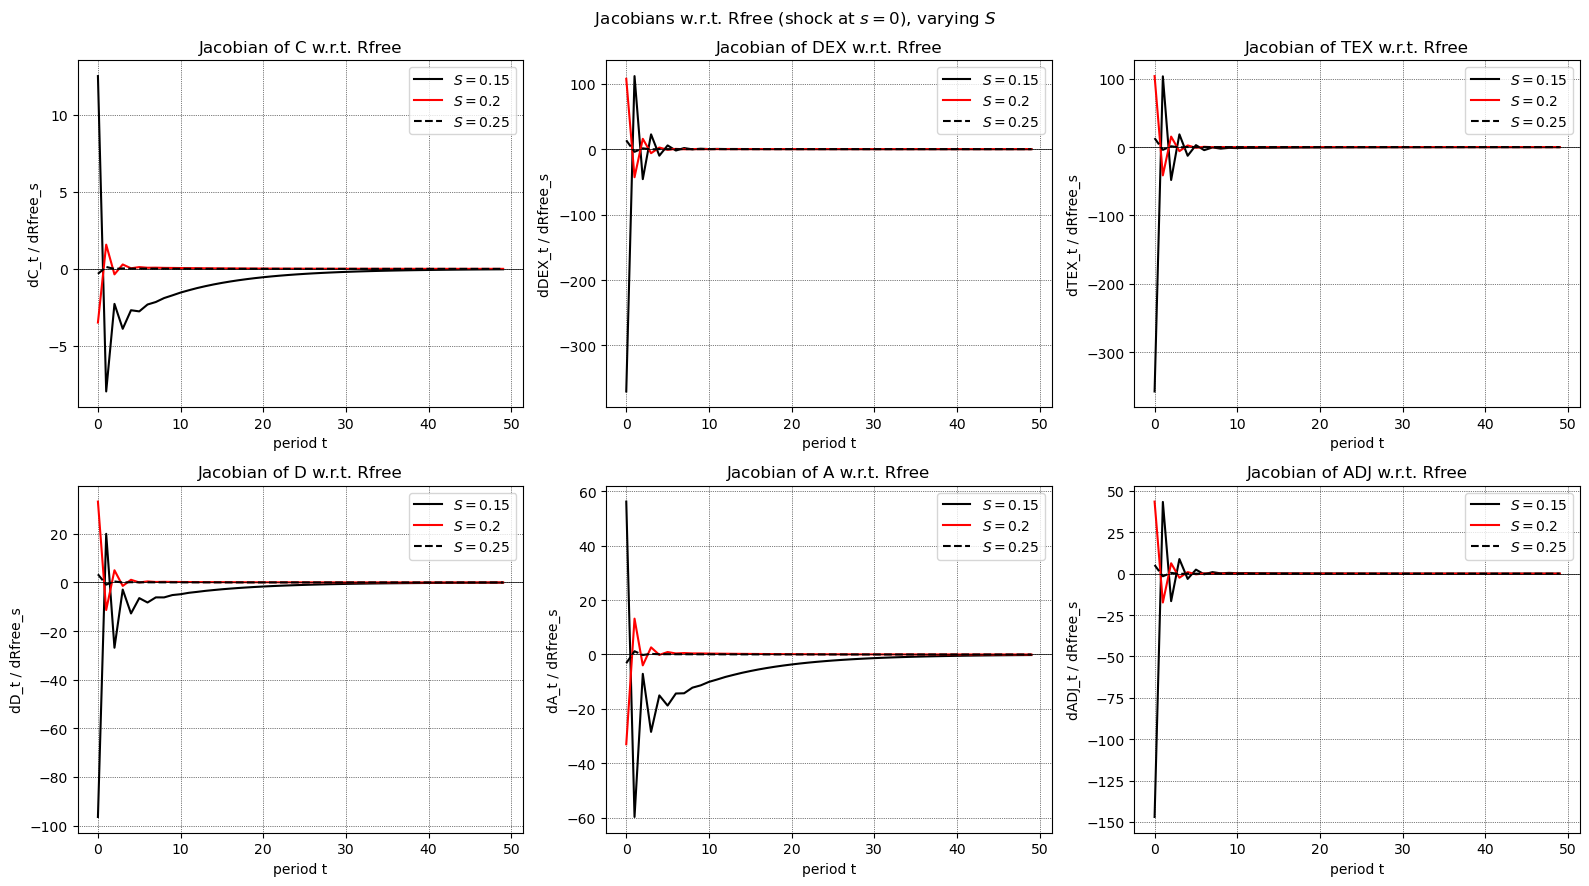

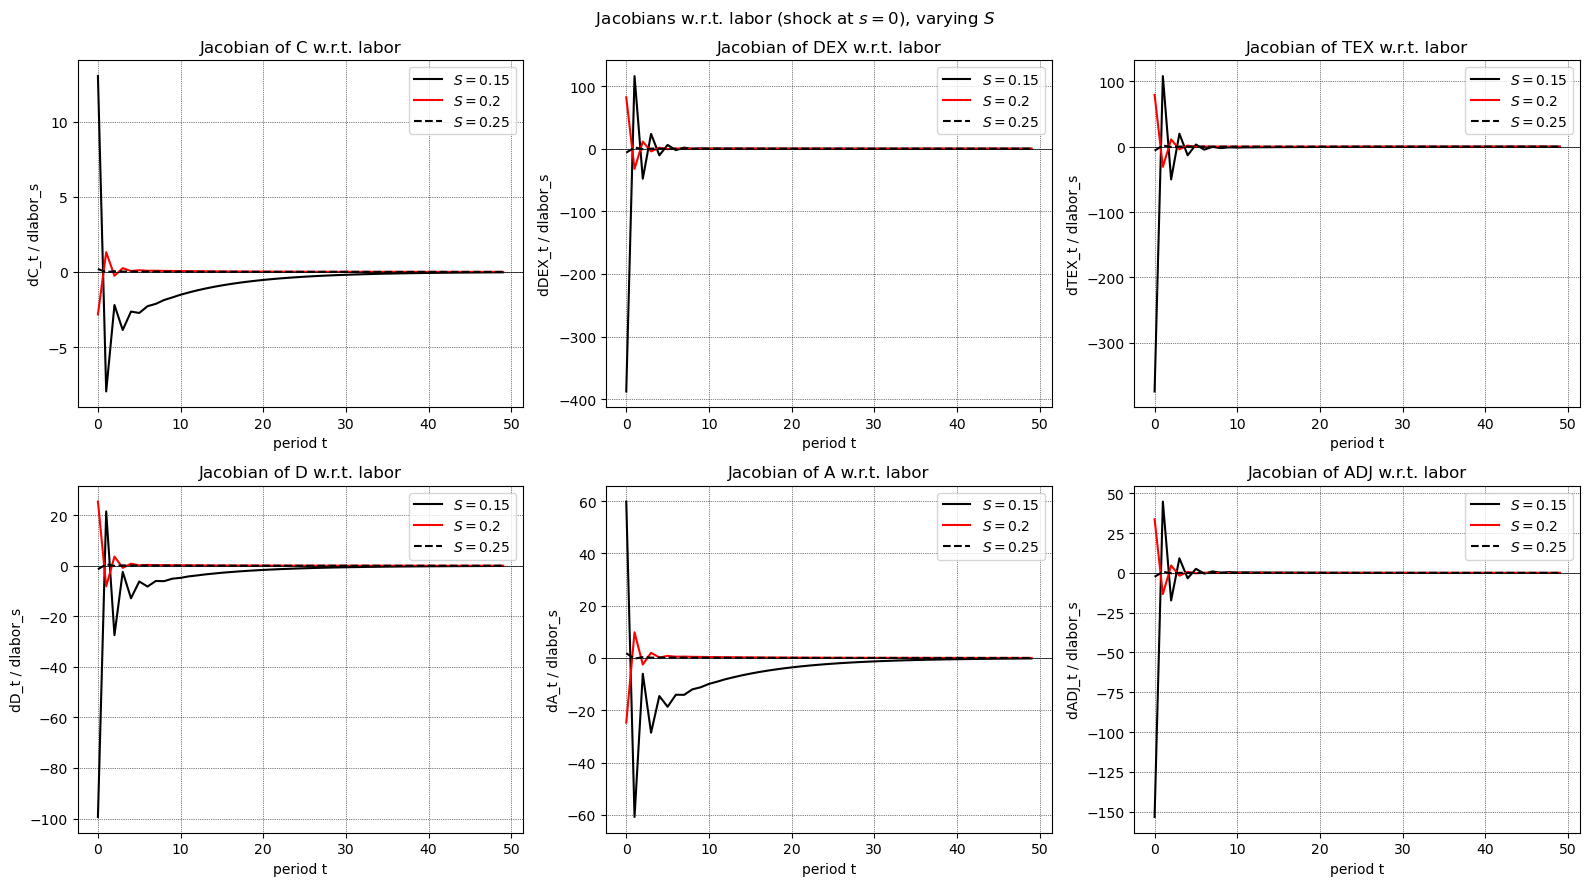

In [6]:
# Overlay Jacobians across parameter values (IRF to period-0 shock)
# Linestyles follow Figures_Durable.ipynb smoothing overlays.
shock_s = 0  # column of Jacobian = date of shock

# --- Rfree ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_Rfree"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. Rfree")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dRfree_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(r"Jacobians w.r.t. Rfree (shock at $s=0$), varying $S$")
fig.tight_layout()
plt.show()

# --- labor ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.flat, JAC_KEYS):
    for r, (color, ls) in zip(results, LINE_STYLES):
        J = r["jacobians_labor"][name]
        ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
    ax.axhline(0.0, color="k", lw=0.5)
    ax.set_title(f"Jacobian of {name} w.r.t. labor")
    ax.set_xlabel("period t")
    ax.set_ylabel(f"d{name}_t / dlabor_s")
    ax.grid(color="k", linestyle=":", linewidth=0.5)
    ax.legend(loc="best")
fig.suptitle(r"Jacobians w.r.t. labor (shock at $s=0$), varying $S$")
fig.tight_layout()
plt.show()


In [7]:
# Save steady states and Jacobians as separate pickles
ss_payload = {
    "channel": results[0]["channel"],
    "param_name": results[0]["param_name"],
    "param_col": results[0]["param_col"],
    "param_values": [r["param"] for r in results],
    "labels": [r["label"] for r in results],
    "steady_states": {r["param"]: r["ss"] for r in results},
    "kink_euler": {r["param"]: r["kink_euler"] for r in results},
    "kink_euler_t": 0,
    "ss_table": ss_table,
}

jac_meta = dict(
    channel=results[0]["channel"],
    param_name=results[0]["param_name"],
    param_col=results[0]["param_col"],
    param_values=[r["param"] for r in results],
    labels=[r["label"] for r in results],
    T=T,
    shock_s_plotted=0,
)

jac_payload_Rfree = {
    **jac_meta,
    "shk_param": "Rfree",
    "jacobians": {r["param"]: r["jacobians_Rfree"] for r in results},
}
jac_payload_labor = {
    **jac_meta,
    "shk_param": "labor",
    "jacobians": {r["param"]: r["jacobians_labor"] for r in results},
}

ss_path = OUT_DIR / "DurableModel_Search_Inf_SS.pkl"
jac_path_Rfree = OUT_DIR / "DurableModel_Search_Inf_Jacobians_Rfree.pkl"
jac_path_labor = OUT_DIR / "DurableModel_Search_Inf_Jacobians_labor.pkl"
with open(ss_path, "wb") as f:
    pickle.dump(ss_payload, f)
with open(jac_path_Rfree, "wb") as f:
    pickle.dump(jac_payload_Rfree, f)
with open(jac_path_labor, "wb") as f:
    pickle.dump(jac_payload_labor, f)

elapsed = time.time() - start_time
print(f"Saved {ss_path.resolve()}")
print(f"Saved {jac_path_Rfree.resolve()}")
print(f"Saved {jac_path_labor.resolve()}")
print("Done in", str(datetime.timedelta(seconds=elapsed)))


Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Search_Inf_SS.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Search_Inf_Jacobians_Rfree.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Search_Inf_Jacobians_labor.pkl
Done in 0:13:59.688470


In [8]:
model.solution[0].xAdj_pre_list

[array([ 6.94594511,  7.1494666 ,  7.35902899,  7.57508726,  7.7980066 ,
         8.09196735,  8.53274476,  9.17216493,  9.85725565, 10.59431095,
        11.40071215, 12.29553851, 13.30054867, 14.445766  , 15.74959102,
        17.16018626, 18.61483933, 20.11341674, 21.68513405])]

In [9]:
model.distance

6.983909706158904e-09

In [10]:
J_C_labor[0,0]

0.19061269019404747

In [11]:
J_TEX_labor[0,0]

-6.0495902907936605

In [12]:
J_ADJ_labor[0,0]

-2.4189756172547647